# Imports

In [174]:
import os
os.environ["KERAS_BACKEND"] = "torch"

import torch
import keras
import numpy as np
import pandas as pd
import transformers
import tensorflow as tf
import tqdm.notebook as tqdm
import sklearn.model_selection
import sklearn.metrics
import sklearn.manifold
import sklearn.decomposition
import matplotlib.pyplot as plt

import gc, sys, traceback

In [9]:
with torch.no_grad():
    torch.cuda.empty_cache()
torch.cuda.empty_cache()
if hasattr(sys, "last_traceback") and sys.last_traceback:
    traceback.clear_frames(sys.last_traceback)
gc.collect(), torch.cuda.memory_allocated(), torch.cuda.memory_reserved()

(1333, 1233088000, 1470103552)

# Data

Load and prepare your dataset. Dataset should have at least 10k samples in it. Each dataset cannot be used by more than two students.

In [3]:
images_train = keras.utils.image_dataset_from_directory(
    directory='dataset/seg_train',
    labels='inferred',
    label_mode='int',
    image_size=(150, 150),
    batch_size=None
)

Found 14034 files belonging to 6 classes.


2026-11-20 22:03:50.754083: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-11-20 22:03:52.935259: W tensorflow/core/common_runtime/gpu/gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was 0.
I0000 00:00:1795176232.935308     719 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9709 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060, pci bus id: 0000:01:00.0, compute capability: 8.6


In [4]:
images_test = keras.utils.image_dataset_from_directory(
    directory='dataset/seg_test',
    labels='inferred',
    label_mode='int',
    image_size=(150, 150),
    batch_size=None
)

Found 3000 files belonging to 6 classes.


In [84]:
N_CLASSES = 6

In [155]:
np.bincount(list(images_train.map(lambda x, y: y).as_numpy_iterator()))

array([2191, 2271, 2404, 2512, 2274, 2382])

In [156]:
np.bincount(list(images_test.map(lambda x, y: y).as_numpy_iterator()))

array([437, 474, 553, 525, 510, 501])

# Backbone

Load pretrained model from Hugging Face (or some other model repository if it's more convenient). Model should be trained on Feature Extraction task.

In [5]:
backbone = transformers.AutoModel.from_pretrained("jinaai/jina-embeddings-v5-omni-nano", trust_remote_code=True, modality="vision").to("cuda")
backbone.device

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 24 files:   0%|          | 0/24 [00:00<?, ?it/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/285 [00:00<?, ?it/s]

device(type='cuda', index=0)

Load tokenizer to be used with the model

In [6]:
processor = transformers.AutoProcessor.from_pretrained("jinaai/jina-embeddings-v5-omni-nano", trust_remote_code=True)

/home/foler/.cache/huggingface/modules/transformers_modules/jinaai/jina_hyphen_embeddings_hyphen_v5_hyphen_omni_hyphen_nano/14b55e6b7004a8b6d53a6a8d2ff3cf69a502bd50/processing_llava_eurobert.py:36: FutureWarning: `Qwen2VLProcessorKwargs` is deprecated and will be removed in version 5.29.0. Use `ProcessingKwargs` instead.
  from transformers.models.qwen2_vl.processing_qwen2_vl import (


In [82]:
EMBED_DIM = 768

# Feature extraction

Since we will not be training the backbone, extract features from your dataset.

Run the backbone on the images and save the extracted features. Don't forget to process the images. Images don't have to be of the same size, though it would be faster if they were. If the images don't fit in memory, lazily load them from disk

In [83]:
def embed(ds, batch_size: int = 32) -> tuple[np.ndarray, np.ndarray]:
    embeds = np.zeros((len(ds), EMBED_DIM))
    labels = np.zeros((len(ds),))

    for i, batch in enumerate(tqdm.tqdm(ds.batch(batch_size))):
        processor_batch = processor(images=[im for im in batch[0].numpy()], text=["<image>"] * len(batch[0]), return_tensors="pt").to(backbone.device)
        embed_batch = backbone.embed(**processor_batch).float().cpu().numpy()
        embeds[i * batch_size : (i+1) * batch_size] = embed_batch
        
        labels[i * batch_size : (i+1) * batch_size] = batch[1].numpy()

    return embeds, labels.astype(int)

In [47]:
embed_train, labels_train = embed(images_train, batch_size=64)

  0%|          | 0/220 [00:00<?, ?it/s]

2026-11-20 22:32:25.881400: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [64]:
np.savez_compressed('./dataset/train.npz', embed_train=embed_train, labels_train=labels_train)

In [65]:
embed_train = np.load('./dataset/train.npz')['embed_train']
labels_train = np.load('./dataset/train.npz')['labels_train']

In [105]:
embed_test, labels_test = embed(images_test, batch_size=64)

  0%|          | 0/47 [00:00<?, ?it/s]

2026-11-20 23:00:24.467709: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [106]:
np.savez_compressed('./dataset/test.npz', embed_test=embed_test, labels_test=labels_test)

In [108]:
embed_test = np.load('./dataset/test.npz')['embed_test']
labels_test = np.load('./dataset/test.npz')['labels_test']

# Prepare train/test data

Prepare `tf.data.Dataset` or some other way for the data to be used during training.

In [110]:
train_X = tf.data.Dataset.from_tensor_slices(embed_train)
train_y = tf.data.Dataset.from_tensor_slices(labels_train)
train_dataset = tf.data.Dataset.zip((train_X, train_y)).batch(128)

test_X = tf.data.Dataset.from_tensor_slices(embed_test)
test_y = tf.data.Dataset.from_tensor_slices(labels_test)
test_dataset = tf.data.Dataset.zip((test_X, test_y)).batch(128)

# Build the model

Build a simple model. The model should accept an extracted feature vector and return a vector of class logits (or probabilities). Model should only have a couple (or even 1) layers with weights.

In [119]:
inputs = x = keras.layers.Input(shape=(EMBED_DIM,), name='input')
x = keras.layers.Dense(N_CLASSES, name='output')(x)
model = keras.models.Model(inputs=inputs, outputs=x, name='SimpleModel')

In [120]:
model.summary()

Model: "SimpleModel"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 768)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 6)              │         4,614 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,614 (18.02 KB)

 Trainable params: 4,614 (18.02 KB)

 Non-trainable params: 0 (0.00 B)

Compile the model. Choose loss and metrics.

In [121]:
model.compile(
    optimizer='adam',
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy'],
)

# Train the model

In [122]:
SAVE_PATH = './saved'

In [123]:
model.fit(
    train_dataset,
    validation_data=test_dataset,
    epochs=10,
    callbacks=[
        keras.callbacks.ModelCheckpoint(
            f'{SAVE_PATH}/{model.name}.keras',
            save_best_only=True,
        )
    ]
)

Epoch 1/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8499 - loss: 1.3411 - val_accuracy: 0.9080 - val_loss: 0.9857
Epoch 2/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9174 - loss: 0.7801 - val_accuracy: 0.9203 - val_loss: 0.6237
Epoch 3/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9238 - loss: 0.5291 - val_accuracy: 0.9273 - val_loss: 0.4564
Epoch 4/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9289 - loss: 0.4067 - val_accuracy: 0.9313 - val_loss: 0.3681
Epoch 5/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9322 - loss: 0.3383 - val_accuracy: 0.9337 - val_loss: 0.3154
Epoch 6/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9338 - loss: 0.2958 - val_accuracy: 0.9343 - val_loss: 0.2812
Epoch 7/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9354 - loss: 0.2673 - val_accuracy: 0.9360 - val_loss: 0.2575
Epoch 8/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9366 - loss: 0.2470 - val_accuracy: 0

# Evaluation

Evalute the model on test data.

In [171]:
images_test.class_names

['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']

In [159]:
y_pred = model.predict(test_dataset)

24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step


Plot confusion matrix.

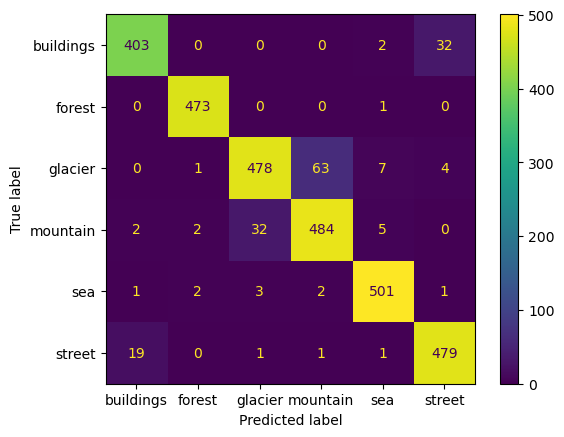

In [172]:
sklearn.metrics.ConfusionMatrixDisplay.from_predictions(labels_test, y_pred.argmax(axis=1), display_labels=images_test.class_names)

Perform dimensiality reduction and plot the extracted features. Do classes form clusters?

In [204]:
tsne_embed = sklearn.manifold.TSNE().fit_transform(embed_test)

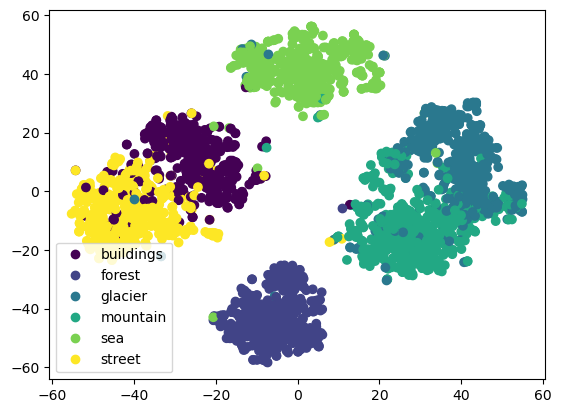

In [205]:
scatter = plt.scatter(tsne_embed[:, 0], tsne_embed[:, 1], c=labels_test)
plt.legend(scatter.legend_elements()[0], images_test.class_names, loc="lower left")

# Bonus

Check if the feature extractor model can be used without a classifier layer (how large is the average feature vector similarity inbetween same in different classes)

In [235]:
embeds = embed_test
labels = labels_test

In [236]:
avg_vectors = np.zeros((N_CLASSES, EMBED_DIM))

np.add.at(avg_vectors, labels, embeds)

avg_vectors /= np.bincount(labels)[:, None]
avg_vectors /= np.linalg.norm(avg_vectors, axis=-1, keepdims=True)

In [237]:
avg_vectors

array([[ 0.02442861,  0.04577089,  0.06828638, ..., -0.02840432,
         0.05215148,  0.03623051],
       [ 0.08105044, -0.03114776,  0.08728795, ..., -0.04230711,
         0.02306693, -0.01681896],
       [ 0.07220539, -0.03460224,  0.09277814, ...,  0.00707455,
        -0.03679565,  0.04804447],
       [ 0.07857672, -0.01319964,  0.0768591 , ...,  0.02123028,
        -0.03115977,  0.04645991],
       [ 0.06053638,  0.00218238,  0.11049273, ..., -0.00400562,
         0.00281661,  0.0360695 ],
       [ 0.01904317,  0.03254502,  0.05892665, ..., -0.02946528,
         0.0370102 ,  0.0483818 ]], shape=(6, 768))

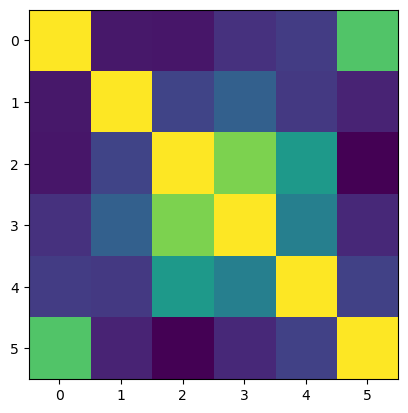

In [220]:
plt.imshow(avg_vectors @ avg_vectors.T)

#### 2?

In [238]:
features = embeds / np.linalg.norm(embeds, axis=-1, keepdims=True)

In [239]:
sim = feats @ feats.T
same = labels[None] == labels[:, None]
eye  = np.eye(len(labels), dtype=np.bool)

intra_mask = same & ~eye
inter_mask = ~same

avg_intra = sim[intra_mask].mean().item()
avg_inter = sim[inter_mask].mean().item()

print(f"Avg intra-class similarity: {avg_intra:.4f}")
print(f"Avg inter-class similarity: {avg_inter:.4f}")
print(f"Gap:  {avg_intra - avg_inter:+.4f}")
print(f"Ratio: {avg_intra / avg_inter:.3f}")

Avg intra-class similarity: 0.7064
Avg inter-class similarity: 0.4113
Gap:  +0.2950
Ratio: 1.717


asd

In [254]:
sklearn.metrics.silhouette_score(features, labels, metric='cosine')

0.2890845182756363